In [6]:
import sys
print("Python running from:", sys.executable)

import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import xgboost as xgb
import torch

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("sklearn:", sklearn.__version__)
print("xgboost:", xgb.__version__)
print("torch:", torch.__version__)

Python running from: c:\Users\Asus\Desktop\VNIT\ndt_xgboost\.venv\Scripts\python.exe
numpy: 2.5.4
pandas: 3.0.6
sklearn: 1.9.1
xgboost: 3.4.1
torch: 2.14.1+cpu


In [7]:
## Data loading and XGBoost baseline
### Imports and seeds

import time, random 
import numpy as np
import pandas as pd
import torch
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [8]:
### Load, subsample, split, standardize

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = fetch_covtype()
X_full, y_full = data.data, data.target - 1
print("Full dataset:", X_full.shape, "| classes:", np.unique(y_full))

X_sub, _, y_sub, _= train_test_split(
    X_full, y_full, train_size=100_000, stratify=y_full, random_state=SEED
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_sub, y_sub, test_size=0.30, stratify=y_sub, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print("\nClass distribution (train):")
print(pd.Series(y_train).value_counts(normalize=True).sort_index().round(4))

Full dataset: (581012, 54) | classes: [0 1 2 3 4 5 6]
Train: (70000, 54) Val: (15000, 54) Test: (15000, 54)

Class distribution (train):
0    0.3646
1    0.4876
2    0.0615
3    0.0047
4    0.0163
5    0.0299
6    0.0353
Name: proportion, dtype: float64


In [9]:
### XGBoost baseline

N_ROUNDS = 200
LR = 0.1
DEPTH = 4

xgb_model = xgb.XGBClassifier(
    n_estimators=N_ROUNDS,
    learning_rate=LR,
    max_depth=DEPTH,
    tree_method="hist",
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1,
)

t0 = time.time()
xgb_model.fit(X_train, y_train, 
              eval_set=[(X_train, y_train), (X_val, y_val)],
              verbose=False)
xgb_time = time.time() - t0

pred_test = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, pred_test)
xgb_f1 = f1_score(y_test, pred_test, average="macro")

print(f"XGBoost | test acc: {xgb_acc:.4f} | macro-F1: {xgb_f1:.4f} | train time: {xgb_time:.1f}s")


XGBoost | test acc: 0.7875 | macro-F1: 0.7114 | train time: 3.8s


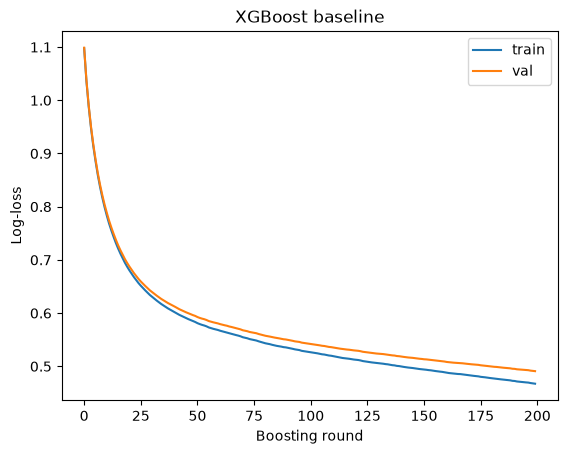

In [10]:
### Learning curve

res = xgb_model.evals_result()
plt.plot(res["validation_0"]["mlogloss"], label="train")
plt.plot(res["validation_1"]["mlogloss"], label="val")
plt.xlabel("Boosting round"); plt.ylabel("Log-loss")
plt.title("XGBoost baseline"); plt.legend(); plt.show()

In [14]:
## Soft decision tree in pytorch

### SoftTree module

import torch.nn as nn

class SoftTree(nn.Module):
    """
    Soft (differentiable) decision tree of fixed depth.
    - 2^depth - 1 internal nodes, each a linear gate: P(left) = sigmoid(w.x + b)
    - 2^depth leaves, each holding a learnable vector of size out_dim
    - output = sum over leaves of P(reach leaf | x) * leaf_value
    """

    def __init__(self, in_features, depth, out_dim):
        super().__init__()
        self.depth = depth
        self.n_internal = 2**depth - 1
        self.n_leaves = 2**depth
        self.gates = nn.Linear(in_features, self.n_internal)
        self.leaf_values = nn.Parameter(0.01 * torch.randn(self.n_leaves, out_dim))

    def leaf_probs(self, x):
        B = x.shape[0]
        logits = self.gates(x)
        path = torch.ones(B, 1, dtype=x.dtype)
        for level in range(self.depth):
            start, end = 2**level -1, 2**(level + 1) - 1
            p_left = torch.sigmoid(logits[:, start:end])
            path = torch.stack([path * p_left, path * (1 - p_left)], dim=2)
            path = path.reshape(B, -1)
        return path

    def forward(self, x):
        return self.leaf_probs(x) @ self.leaf_values

In [15]:
### Sanity checks


tree = SoftTree(in_features=54, depth=4, out_dim=7)
xb = torch.from_numpy(X_train[:5])

lp = tree.leaf_probs(xb)
print("leaf_probs shape:", lp.shape)
print("row sums (should all be ~1):", lp.sum(dim=1))

out = tree(xb)
print("output shape:", out.shape)

out.pow(2).sum().backward()
print("gate grad nonzero:", tree.gates.weight.grad.abs().sum().item() > 0)
print("leaf grad nonzero:", tree.leaf_values.grad.abs().sum().item() > 0)

n_params = sum(p.numel() for p in tree.parameters())
print("parameters in one tree:", n_params)


leaf_probs shape: torch.Size([5, 16])
row sums (should all be ~1): tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)
output shape: torch.Size([5, 7])
gate grad nonzero: True
leaf grad nonzero: True
parameters in one tree: 937


In [17]:
### Standalone traning test

Xtr, ytr = torch.from_numpy(X_train), torch.from_numpy(y_train).long()
Xva, yva = torch.from_numpy(X_val), torch.from_numpy(y_val).long()

torch.manual_seed(SEED)
tree = SoftTree(54, depth=4, out_dim=7)
opt = torch.optim.Adam(tree.parameters(), lr=0.05)
BATCH, EPOCHS = 1024, 15

t0 = time.time()
for epoch in range(EPOCHS):
    perm = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), BATCH):
        idx = perm[i:i + BATCH]
        loss = torch.nn.functional.cross_entropy(tree(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch % 3 == 2 or epoch == EPOCHS - 1:
        with torch.no_grad():
            val_acc = (tree(Xva).argmax(1) == yva).float().mean().item()
        print(f"epoch {epoch+1:2d} | last batch loss {loss.item():.3f} | val acc {val_acc:.4f}")
print(f"time: {time.time() - t0:.1f}s")


epoch  3 | last batch loss 0.638 | val acc 0.7322
epoch  6 | last batch loss 0.648 | val acc 0.7377
epoch  9 | last batch loss 0.615 | val acc 0.7397
epoch 12 | last batch loss 0.589 | val acc 0.7460
epoch 15 | last batch loss 0.578 | val acc 0.7449
time: 1.6s
